## 1. Fase 1 - Comprensión del negocio

### 1.1 Contexto del problema
Un banco realiza campañas de marketing directo (llamadas telefónicas) para ofrecer un **depósito a plazo** a sus clientes. Contactar a todos los clientes es costoso y poco eficiente; identificar a quienes tienen mayor probabilidad de aceptar permite enfocar los recursos comerciales de la campaña.

### 1.2 Objetivo general
Construir un modelo de **clasificación** que estime si un cliente contratará un depósito a plazo (`y`: yes/no) para apoyar la priorización de clientes en campañas de marketing.

### 1.3 Objetivos específicos
- Identificar las variables que se asocian a la contratación del depósito.
- Estimar la probabilidad de contratación de cada cliente.
- Evaluar el desempeño del modelo con datos que no vio durante el entrenamiento (conjunto de prueba).

Alumnos : Tabatha Gamboa - Fabian Parraguez

### 1.4 Criterios de éxito

**Éxito de negocio:**
- Aumentar la tasa de conversión de la campaña contactando primero a los clientes con mayor probabilidad de contratar.
- Reducir el costo comercial evitando llamadas a clientes con baja probabilidad.

**Éxito técnico:**
- `Recall` de la clase `yes` mayor o igual a 0.50 (detectar al menos la mitad de los clientes que sí contratan).
- `ROC-AUC` mayor o igual a 0.90 como referencia de capacidad discriminante.

### 1.5 Supuestos y restricciones
- Se asume que el dataset (`bank-full.csv`, campañas de marketing de una entidad bancaria) representa adecuadamente a los clientes de la campaña.
- El target es binario (`y`: yes/no) y está **desbalanceado** (la clase `yes` es minoritaria).
- La variable `duration` (duración de la última llamada) solo se conoce una vez realizada la llamada; por lo tanto, el modelo sirve para **evaluar el potencial del cliente durante o después del contacto**, no para decidir a quién llamar antes de la campaña.
- No se cuenta con costos reales de la campaña, por lo que el criterio de éxito es técnico.

### 1.6 Plan de iteraciones
Según lo indicado para el Taller 6, se desarrolla **1 iteración completa** de CRISP-DM:
1. **Iteración única:** análisis exploratorio, preparación con `ColumnTransformer`, `Pipeline` con `RandomForestClassifier`, evaluación en el conjunto de prueba y plan de despliegue.

## 2. Fase 2 - Comprensión de los datos

In [29]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

In [30]:
# Cargar el dataset bank-full.csv
df = pd.read_csv('../Data/bank-full.csv', sep=';')

print('Dimensiones:', df.shape)
print('Columnas:')
print(df.columns.tolist())

df.head()

Dimensiones: (45211, 17)
Columnas:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [31]:
# Estructura y tipos de datos
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 8.1 MB


In [32]:
# Calidad de datos: valores faltantes y duplicados
missing = df.isna().sum().sort_values(ascending=False)
missing = missing[missing > 0]

print('Valores faltantes por columna (solo > 0):')
print(missing if len(missing) > 0 else 'No se detectan nulos explícitos.')

print('\nDuplicados totales:', df.duplicated().sum())

Valores faltantes por columna (solo > 0):
No se detectan nulos explícitos.

Duplicados totales: 0


y
no     39922
yes     5289
Name: count, dtype: int64
y
no    0.8830
yes   0.1170
Name: proportion, dtype: float64


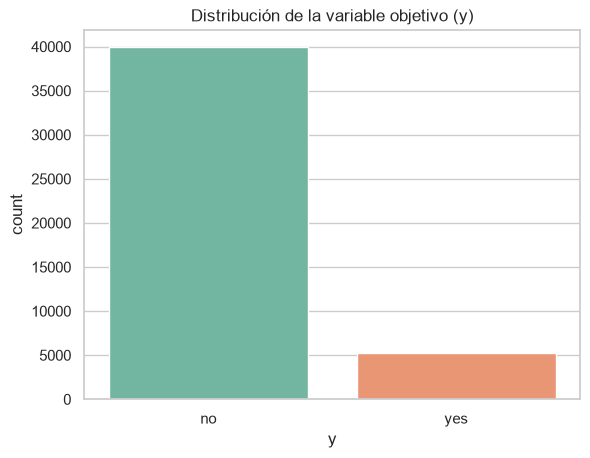

In [33]:
# Revisión de la variable objetivo
print(df['y'].value_counts(dropna=False))
print(df['y'].value_counts(normalize=True, dropna=False).round(4))

sns.countplot(data=df, x='y', palette='Set2')
plt.title('Distribución de la variable objetivo (y)')
plt.show()

**Explicación del gráfico:** el gráfico de barras muestra cuántos clientes contrataron el depósito a plazo (`yes`) y cuántos no (`no`). La barra de `no` es mucho más alta: solo cerca del 12% de los clientes contrata. Esto significa que las clases están **desbalanceadas**, por lo que la Accuracy por sí sola no es una buena medida y se deben revisar Precision, Recall y F1 de la clase `yes`.

In [6]:
# Resumen descriptivo de variables numéricas
df.describe(include=[np.number]).T

,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0


### 2.1 Hallazgos iniciales de la fase de comprensión de datos
- El dataset contiene **45.211 registros** y **17 columnas** (16 variables predictoras y el target `y`).
- El problema es de **clasificación binaria** (`y`) y existe **desbalance de clases**: aproximadamente 88% `no` y 12% `yes`.
- No hay valores nulos ni filas duplicadas.
- Las variables categóricas (`job`, `marital`, `education`, `default`, `housing`, `loan`, `contact`, `month`, `poutcome`) deberán codificarse antes del modelado.
- Las variables numéricas tienen escalas muy distintas (por ejemplo `balance` vs `age`), por lo que se estandarizarán.
- `duration` solo se conoce una vez realizada la llamada, por lo que debe interpretarse con cuidado.

## 3. Fase 3 - Preparación de los datos

Se separan las variables predictoras del target (`yes` = 1, `no` = 0), se codifican las variables categóricas con `pd.get_dummies(..., drop_first=True)` y se divide en entrenamiento (80%) y prueba (20%) de forma estratificada. La estandarización de las variables numéricas se define con un `ColumnTransformer` con `StandardScaler`.

In [34]:
# Target binario (yes = 1, no = 0) y variables predictoras
y = df['y'].map({'yes': 1, 'no': 0})
X = df.drop(columns=['y'])

num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X.select_dtypes(exclude=[np.number]).columns.tolist()

# Codificación de variables categóricas
X = pd.get_dummies(X, columns=cat_cols, drop_first=True)
print('Dimensiones de X:', X.shape)

Dimensiones de X: (45211, 42)


In [35]:
# División estratificada en entrenamiento (80%) y prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print('Entrenamiento:', X_train.shape)
print('Prueba:', X_test.shape)

Entrenamiento: (36168, 42)
Prueba: (9043, 42)


In [36]:
# ColumnTransformer: escalado de variables numéricas (el resto pasa sin cambios)
preprocessor = ColumnTransformer(
    transformers=[('num', StandardScaler(), num_cols)],
    remainder='passthrough'
)

preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. 

## 4. Fase 4 - Modelado

Se construye un `Pipeline` de scikit-learn que encapsula el preprocesamiento y el modelo predictivo (`RandomForestClassifier`).

In [37]:
# Pipeline: preprocesamiento + Random Forest
model_pipeline = Pipeline(steps=[
    ('preprocesamiento', preprocessor),
    ('modelo', RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1))
])

model_pipeline.fit(X_train, y_train)
model_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesamiento', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](42,)","['age','balance','day',...,'poutcome_other','poutcome_success', 'poutcome_unknown']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,42
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, a

## 5. Fase 5 - Evaluación

Se mide el rendimiento del modelo sobre el **conjunto de prueba**, que no participó en el entrenamiento.

In [38]:
# Predicciones sobre el conjunto de prueba
y_pred = model_pipeline.predict(X_test)
y_proba = model_pipeline.predict_proba(X_test)[:, 1]

print('=== Reporte de clasificación (conjunto de prueba) ===')
print(classification_report(y_test, y_pred))

roc_auc = roc_auc_score(y_test, y_proba)
print(f'ROC-AUC: {roc_auc:.4f}')

=== Reporte de clasificación (conjunto de prueba) ===
              precision    recall  f1-score   support

           0       0.92      0.97      0.95      7985
           1       0.66      0.39      0.49      1058

    accuracy                           0.91      9043
   macro avg       0.79      0.68      0.72      9043
weighted avg       0.89      0.91      0.89      9043

ROC-AUC: 0.9293


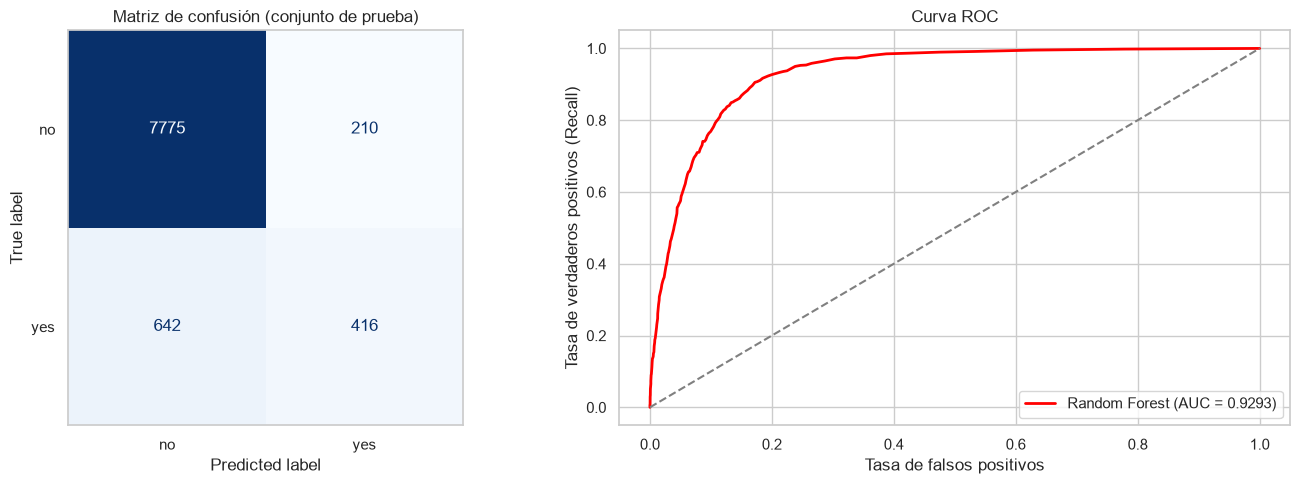

In [39]:
# Matriz de confusión y curva ROC
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=['no', 'yes']).plot(ax=axes[0], cmap='Blues', values_format='d', colorbar=False)
axes[0].set_title('Matriz de confusión (conjunto de prueba)')
axes[0].grid(False)

fpr, tpr, _ = roc_curve(y_test, y_proba)
axes[1].plot(fpr, tpr, color='red', lw=2, label=f'Random Forest (AUC = {roc_auc:.4f})')
axes[1].plot([0, 1], [0, 1], color='gray', linestyle='--')
axes[1].set_xlabel('Tasa de falsos positivos')
axes[1].set_ylabel('Tasa de verdaderos positivos (Recall)')
axes[1].set_title('Curva ROC')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()

**Explicación de los gráficos:**
- **Matriz de confusión (izquierda):** la diagonal muestra los aciertos (clientes `no` bien clasificados y clientes `yes` bien clasificados). La celda inferior izquierda son los clientes que sí contrataron pero el modelo predijo `no` (falsos negativos); la superior derecha son los que el modelo predijo `yes` y no contrataron (falsos positivos). Se observa que los falsos negativos son más que los aciertos de la clase `yes`, lo que explica el Recall bajo.
- **Curva ROC (derecha):** muestra la tasa de verdaderos positivos frente a la de falsos positivos para distintos umbrales. Mientras más se aleja la curva roja de la diagonal gris (modelo aleatorio) y más se acerca a la esquina superior izquierda, mejor discrimina el modelo. El AUC cercano a 0.93 indica una muy buena capacidad para separar a los clientes que contratan de los que no.

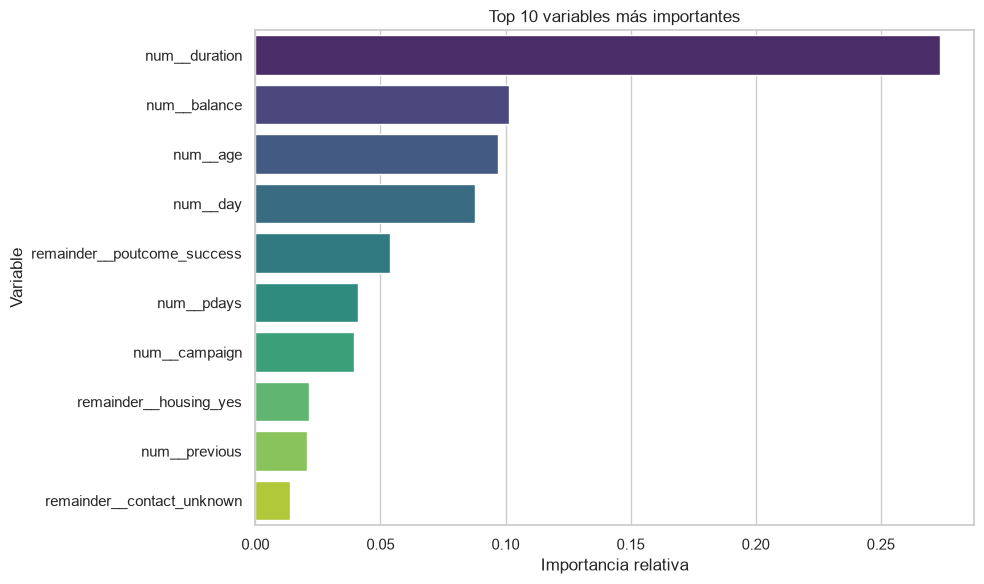

=== Top 10 importancias ===
                      Variable  Importancia
0                num__duration       0.2736
1                 num__balance       0.1015
2                     num__age       0.0971
3                     num__day       0.0876
4  remainder__poutcome_success       0.0540
5                   num__pdays       0.0408
6                num__campaign       0.0396
7       remainder__housing_yes       0.0216
8                num__previous       0.0206
9   remainder__contact_unknown       0.0139


In [40]:
# Importancia de variables del Random Forest
nombres = model_pipeline.named_steps['preprocesamiento'].get_feature_names_out()
importancias = model_pipeline.named_steps['modelo'].feature_importances_

feature_imp_df = pd.DataFrame({
    'Variable': nombres,
    'Importancia': importancias
}).sort_values(by='Importancia', ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importancia', y='Variable', data=feature_imp_df.head(10),
            palette='viridis', hue='Variable', legend=False)
plt.title('Top 10 variables más importantes')
plt.xlabel('Importancia relativa')
plt.ylabel('Variable')
plt.tight_layout()
plt.show()

print('=== Top 10 importancias ===')
print(feature_imp_df.head(10))

**Explicación del gráfico:** las barras muestran qué variables usa más el Random Forest para decidir. Mientras más larga la barra, mayor es su aporte a las predicciones. `duration` (duración de la llamada) destaca claramente, seguida de `balance`, `age`, `day` y `poutcome_success` (resultado exitoso de una campaña anterior). La importancia indica asociación con la predicción, no causalidad.

### 5.1 Interpretación de resultados

- **Capacidad discriminante:** el modelo obtiene un **ROC-AUC de 0.9293**, por lo que cumple el criterio técnico (≥ 0.90). Distingue muy bien entre clientes que contratan y los que no.
- **Accuracy:** 0.91, pero este valor es engañoso por el desbalance de clases (un modelo que siempre predijera `no` obtendría cerca de 0.88). Por eso se priorizan Precision, Recall y F1 de la clase `yes`.
- **Clase `yes`:** Precision **0.66**, Recall **0.39** y F1 **0.49**. El modelo detecta menos de la mitad de los clientes que sí contrataron (matriz de confusión).
- **Criterio de Recall:** el Recall de 0.39 **no alcanza** la meta de 0.50. El modelo es conservador: cuando predice `yes` acierta con frecuencia (Precision 0.66), pero deja pasar a muchos clientes interesados.
- **Variables más importantes:** `duration` es, con diferencia, la más influyente (cerca de 27% de la importancia), seguida de `balance`, `age`, `day` y `poutcome_success`. Hay que recordar que `duration` solo se conoce tras la llamada.
- **Revisión de negocio:** el modelo sirve para priorizar clientes con alta probabilidad (alta precisión), pero para cumplir la meta de Recall se requeriría, en una futura iteración, mejorar el modelo (por ejemplo, tratar el desbalance de clases). Esas mejoras quedan fuera de esta única iteración.

## 6. Fase 6 - Despliegue

#### Resumen y Plan de Despliegue:
1. **Conclusión:** se completó una iteración de CRISP-DM con un `Pipeline` (`ColumnTransformer` + `RandomForestClassifier`) sobre `bank-full.csv`. El modelo alcanzó un ROC-AUC de 0.9293 (cumple la meta ≥ 0.90) y una Precision de 0.66 para la clase `yes`, pero un Recall de 0.39 (no cumple la meta ≥ 0.50), debido al desbalance de clases (≈ 12% de `yes`). La variable más influyente es `duration`.
2. **Plan de despliegue:** guardar el `Pipeline` completo (preprocesamiento + modelo) en la carpeta `Modelos/` y utilizarlo desde la aplicación Streamlit para consultar la probabilidad de contratación de un cliente nuevo ingresando las mismas 16 variables del dataset.
3. **Uso recomendado:** emplear la probabilidad para ordenar a los clientes por potencial de contratación y priorizar el contacto comercial, considerando que `duration` solo está disponible una vez realizada la llamada.
4. **Monitoreo y mejora:** vigilar periódicamente Recall y Precision de la clase `yes` con datos nuevos y reentrenar el modelo si el desempeño cae. Como mejora futura se sugiere tratar el desbalance de clases para elevar el Recall.
5. **Consideraciones éticas:** el modelo estima asociaciones históricas, no causalidad; antes de usarlo en decisiones comerciales conviene revisar que no discrimine a grupos de clientes (por ejemplo, por edad o tipo de empleo).